# Healthy-vs-cancer whole-gland shape analysis (stage 6)

The exploratory SSM (`explore_shapes.ipynb`) models *healthy* glands only. This notebook adds
the project's headline question: **do prostate glands that harbour clinically significant
cancer have a systematically different whole-gland shape than benign ones?**

We run it **within Prostate158** (83 cancer + 56 healthy, same center and segmentation
protocol) so a group difference can't be a cross-dataset confound. A case's *lesion* mask only
sets its group label (`is_cancer`); the geometry modelled is the whole gland, exactly as in the
healthy pipeline.

**Setup** — same as `explore_shapes.ipynb`: `pip install -e ".[dev,analysis]"`, and run this
from the **ShapeWorks** environment (`import shapeworks` + `shapeworks` CLI on PATH) for the
correspondence cell. Every other cell works without it.

> **Caveat.** The correspondence here is the same throwaway-quality pass as the exploratory
> SSM — treat any group effect as *suggestive*, not a validated biomarker.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from shape_modeling.io.reader import discover_cases
from shape_modeling.analysis import (
    build_grouped_cohort, clean_mask, extract_surface, CleanConfig,
    gpa, build_ssm, compare_groups,
)

# --- edit this path ---
PROSTATE158_DIR = Path("../Prostate158")
WORK_DIR = Path("../shapeworks_work_prostate158_grouped")  # cached particles for the grouped cohort

TOP_K = 10  # leading (variance-ordered) modes used for the per-mode family and the omnibus test

## 1. Build the grouped cohort

`build_grouped_cohort` keeps **every** case with an organ seg and tags it
`is_cancer = bool(case.cancer_segs)`. We run it on Prostate158 alone (don't pool datasets here:
mixing segmentation protocols would reintroduce a confound). `is_cancer`, `volumes`, and the
later score rows all share the cohort's subject order.

In [2]:
ds = discover_cases(PROSTATE158_DIR, default_mri_type="T2W")
cohort = build_grouped_cohort({"Prostate158": ds})

is_cancer = np.array([e.is_cancer for e in cohort])
volumes = np.array([e.volume_cm3 for e in cohort])
print(f"Grouped cohort: {len(cohort)} cases "
      f"({int((~is_cancer).sum())} healthy / {int(is_cancer.sum())} cancer)")

Grouped cohort: 139 cases (56 healthy / 83 cancer)


## 2. Sanity check — one gland per group

Clean the mask (largest component, fill holes) and triangulate in physical mm, just to confirm
both groups give sensible surfaces before correspondence.

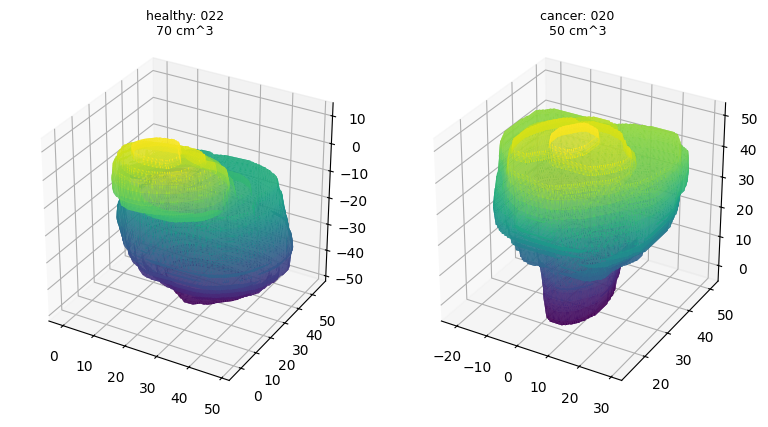

In [3]:
clean_cfg = CleanConfig(keep_largest=True, fill_holes=True, smooth_sigma=1.0)
examples = [next(e for e in cohort if not e.is_cancer), next(e for e in cohort if e.is_cancer)]

fig = plt.figure(figsize=(8, 4))
for i, e in enumerate(examples):
    surf = extract_surface(clean_mask(e.organ.array, clean_cfg), e.organ)
    ax = fig.add_subplot(1, 2, i + 1, projection="3d")
    ax.plot_trisurf(surf.verts[:, 0], surf.verts[:, 1], surf.faces, surf.verts[:, 2],
                    cmap="viridis", linewidth=0, antialiased=True)
    ax.set_title(f"{'cancer' if e.is_cancer else 'healthy'}: {e.case_id}\n{e.volume_cm3:.0f} cm^3",
                 fontsize=9)
    ax.set_box_aspect((1, 1, 1))
plt.tight_layout(); plt.show()

## 3. Particle correspondence (ShapeWorks)

Same optimizer as the healthy pipeline, cached in `WORK_DIR/particles.npz`. The assert keeps the
particle rows aligned with `is_cancer` / `volumes`.

> Requires ShapeWorks. If `import shapeworks` fails, see the setup note at the top.

In [4]:
from shape_modeling.analysis import run_shapeworks, ShapeWorksConfig

sw_cfg = ShapeWorksConfig(num_particles=512, iterations=1000, work_dir=WORK_DIR)
system = run_shapeworks(cohort, sw_cfg)        # (S, M, 3); cached after first run
print("particles:", system.particles.shape, "for", len(system.case_ids), "subjects")
assert system.case_ids == [e.case_id for e in cohort]   # rows align with is_cancer / volumes

particles: (139, 512, 3) for 139 subjects


## 4. Procrustes align + PCA

**`scale=False`** (per the analysis decision): gland size is kept in the model, so a group
difference may reflect size and/or shape combined. The raw size gap is reported separately in
step 7.

In [5]:
aligned, mean_shape = gpa(system.particles, scale=False)
model = build_ssm(aligned)
print(f"{model.n_modes} modes over {model.n_points} points")
print("variance explained by first 5 modes:",
      np.round(model.explained_variance_ratio[:5], 3))

138 modes over 512 points
variance explained by first 5 modes: [0.413 0.133 0.099 0.065 0.045]


## 5. Group comparison

`compare_groups` bundles the whole analysis: per-mode Mann-Whitney + Cohen's d (FDR-corrected),
the omnibus "does shape predict cancer?" permutation test, the group-mean-difference shape, and
the descriptive volume gap.

In [6]:
result = compare_groups(model, is_cancer, cohort=cohort, top_k=TOP_K, n_permutations=1000, seed=0)

print(f"{result.n_healthy} healthy vs {result.n_cancer} cancer\n")
print(f"Omnibus  'does gland shape predict cancer?'  CV AUC = {result.omnibus.auc:.3f}  "
      f"(permutation p = {result.omnibus.p_value:.3f}, top {result.omnibus.top_k} modes)")
sig = result.significant_modes()
print(f"Modes differing after FDR (alpha=0.05): {[t.mode + 1 for t in sig] or 'none'}")

56 healthy vs 83 cancer

Omnibus  'does gland shape predict cancer?'  CV AUC = 0.537  (permutation p = 0.316, top 10 modes)
Modes differing after FDR (alpha=0.05): none


### Mode scores by group

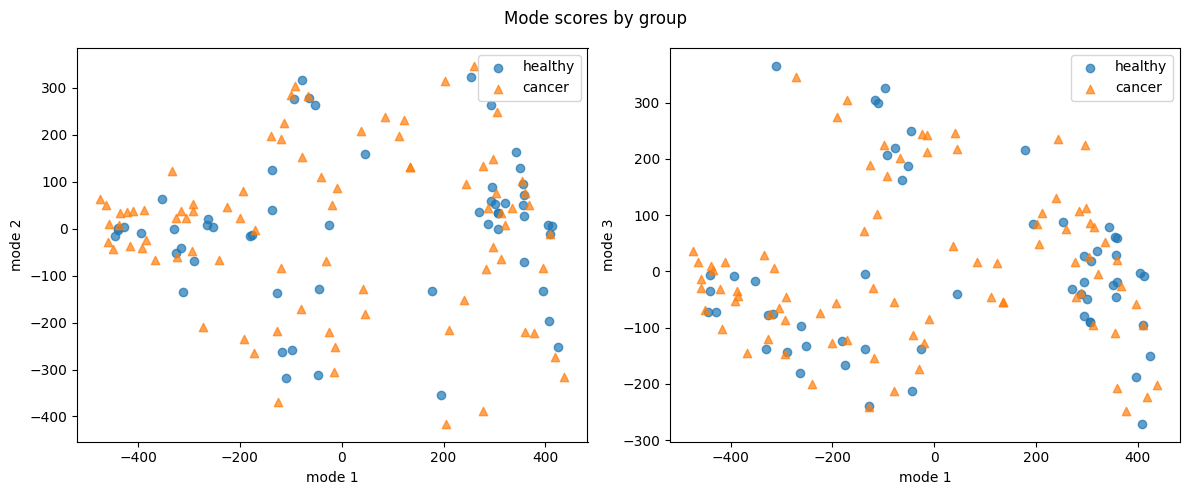

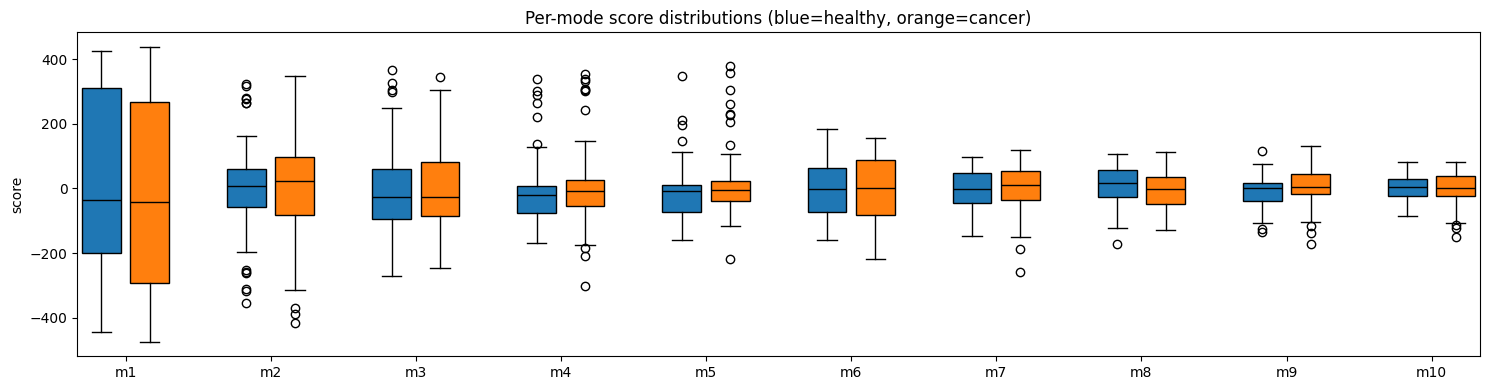

In [7]:
sc_healthy, sc_cancer = model.scores[~is_cancer], model.scores[is_cancer]

pairs = [(0, 1), (0, 2)]
fig, axes = plt.subplots(1, len(pairs), figsize=(6 * len(pairs), 5))
for ax, (a, b) in zip(np.atleast_1d(axes), pairs):
    ax.scatter(sc_healthy[:, a], sc_healthy[:, b], label="healthy", alpha=0.7)
    ax.scatter(sc_cancer[:, a], sc_cancer[:, b], label="cancer", alpha=0.7, marker="^")
    ax.set(xlabel=f"mode {a+1}", ylabel=f"mode {b+1}")
    ax.legend()
fig.suptitle("Mode scores by group"); plt.tight_layout(); plt.show()

# Per-mode score distributions for the tested modes (blue = healthy, orange = cancer).
k = result.omnibus.top_k
fig, ax = plt.subplots(figsize=(1.5 * k, 4))
for m in range(k):
    ax.boxplot(sc_healthy[:, m], positions=[m * 3], widths=0.8, patch_artist=True,
               boxprops=dict(facecolor="C0"), medianprops=dict(color="k"))
    ax.boxplot(sc_cancer[:, m], positions=[m * 3 + 1], widths=0.8, patch_artist=True,
               boxprops=dict(facecolor="C1"), medianprops=dict(color="k"))
ax.set_xticks([m * 3 + 0.5 for m in range(k)])
ax.set_xticklabels([f"m{m+1}" for m in range(k)])
ax.set_ylabel("score"); ax.set_title("Per-mode score distributions (blue=healthy, orange=cancer)")
plt.tight_layout(); plt.show()

### Per-mode statistics

`*` marks modes whose FDR-adjusted p-value is below 0.05. `cohen_d` is cancer minus healthy
(positive = cancer scores higher on that mode).

In [8]:
print(f"{'mode':>4} {'p_raw':>8} {'p_adj':>8} {'cohen_d':>8} {'mean_H':>9} {'mean_C':>9}")
print("-" * 52)
for t in result.mode_tests:
    flag = " *" if t.p_adjusted < 0.05 else ""
    print(f"{t.mode+1:>4} {t.p_value:>8.3f} {t.p_adjusted:>8.3f} {t.cohens_d:>8.2f} "
          f"{t.mean_healthy:>9.2f} {t.mean_cancer:>9.2f}{flag}")

mode    p_raw    p_adj  cohen_d    mean_H    mean_C
----------------------------------------------------
   1    0.163    0.327    -0.23     40.17    -27.10
   2    0.828    0.926    -0.03      2.65     -1.79
   3    0.549    0.784     0.06     -5.41      3.65
   4    0.157    0.327     0.10     -7.13      4.81
   5    0.146    0.327     0.23    -13.10      8.84
   6    0.926    0.926    -0.03      1.81     -1.22
   7    0.524    0.784     0.05     -1.93      1.30
   8    0.042    0.327    -0.32     11.01     -7.43
   9    0.089    0.327     0.30     -9.43      6.36
  10    0.869    0.926    -0.02      0.58     -0.39


### Omnibus ROC

Out-of-fold ROC for the logistic model used by the permutation test. A curve hugging the
diagonal (AUC ~ 0.5) means gland shape does **not** distinguish the groups in this cohort.

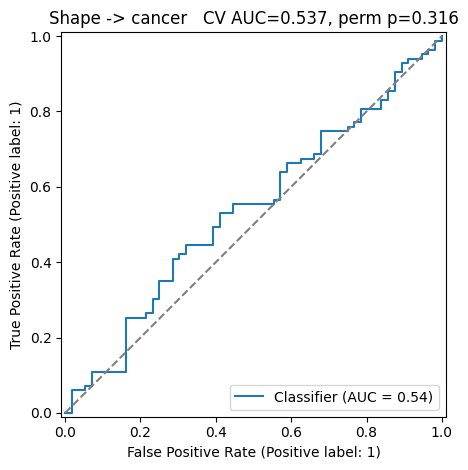

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import RocCurveDisplay
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X = model.scores[:, : result.omnibus.top_k]
y = is_cancer.astype(int)
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
cv = StratifiedKFold(n_splits=result.omnibus.n_splits, shuffle=True, random_state=0)
oof = cross_val_predict(clf, X, y, cv=cv, method="predict_proba")[:, 1]

RocCurveDisplay.from_predictions(y, oof)
plt.plot([0, 1], [0, 1], "--", c="grey")
plt.title(f"Shape -> cancer   CV AUC={result.omnibus.auc:.3f}, perm p={result.omnibus.p_value:.3f}")
plt.tight_layout(); plt.show()

### Where the group mean glands differ

Per-point displacement (mm) between the reconstructed cancer-group and healthy-group mean
glands, painted on the healthy mean. Hot spots show *where* on the gland the groups diverge.

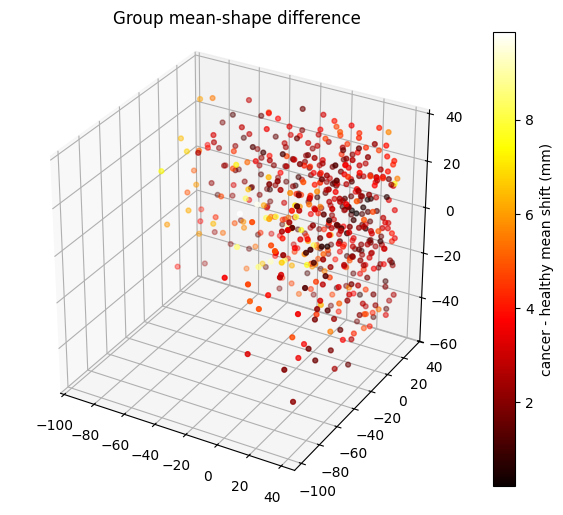

per-point mean shift: max 9.86 mm, mean 3.22 mm


In [10]:
mean_h, _mean_c, delta = result.mean_healthy, result.mean_cancer, result.mean_delta
disp = np.linalg.norm(delta, axis=1)  # per-point shift magnitude (mm)

fig = plt.figure(figsize=(6, 5))
ax = fig.add_subplot(111, projection="3d")
p = ax.scatter(mean_h[:, 0], mean_h[:, 1], mean_h[:, 2], c=disp, cmap="hot", s=12)
fig.colorbar(p, ax=ax, label="cancer - healthy mean shift (mm)")
ax.set_title("Group mean-shape difference"); ax.set_box_aspect((1, 1, 1))
plt.tight_layout(); plt.show()
print(f"per-point mean shift: max {disp.max():.2f} mm, mean {disp.mean():.2f} mm")

### Gland volume by group (size, reported separately)

Because the model keeps size (`scale=False`), it helps to see the raw volume gap on its own.

In [11]:
vd = result.volume
print(f"Gland volume (cm^3):  healthy median {vd.median_healthy:.1f}  |  "
      f"cancer median {vd.median_cancer:.1f}")
print(f"Mann-Whitney p = {vd.p_value:.4f}    Cohen's d = {vd.cohens_d:.2f}  "
      f"(n = {vd.n_healthy} healthy / {vd.n_cancer} cancer)")

Gland volume (cm^3):  healthy median 59.0  |  cancer median 47.1
Mann-Whitney p = 0.0013    Cohen's d = -0.62  (n = 56 healthy / 83 cancer)


**Read-out.** A significant mode (or AUC clearly above 0.5 with a small permutation p) means
benign and cancer glands differ in whole-gland shape — read the group-mean-difference plot to
see *where*, and check the volume gap to judge how much is size vs shape. Near-chance AUC with
no surviving modes means whole-gland shape does not separate the groups in this cohort (a
genuine, publishable negative). Either way this is exploratory — the correspondence is the
throwaway-quality first pass.

**Scaling up later — PI-CAI.** PI-CAI is a much larger within-dataset cancer/benign cohort
(~425 csPCa / ~1075 benign, human lesion labels). It drops into this exact flow as one more key
into `build_grouped_cohort` once a loader co-locates its (AI) whole-gland masks with its (human)
lesion masks. Two cautions: its gland masks are AI-derived, so **don't pool** them with
Prostate158's human masks in one model; and watch for RUMC/Radboud patient overlap with
SAML:RUNMC / PROMISE12 before comparing across datasets.